In [132]:
import os
while "src" not in os.listdir():
    os.chdir("..")
    
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import pandas as pd
 
import mygene

from src.reading_in import read_in_proteins, _load_essential_proteins

In [133]:
exclude_proteins = [
    "YBR010W", "YJL177W", "YGR220C", "YIL018W"
]

good_proteins = [
    "YHL027W", "YDR320C"
]

In [134]:
PEP5 = "YMR231W"
G = read_in_proteins(connected=True)
essential_proteins = _load_essential_proteins("data/raw/EssentialProteins_YeastMine_cerevisiae.csv")

MIN_DISTANCE = 4
MAX_DISTANCE = np.inf

distances = nx.single_source_shortest_path_length(G, PEP5)

# Select proteins whose shortest-path distance is 3, 4, or 5
candidate_nodes = {
    node: distance
    for node, distance in distances.items()
    if MIN_DISTANCE <= distance <= MAX_DISTANCE
    and node not in essential_proteins # no essential proteins!
}

communities = nx.community.louvain_communities(G, resolution=40, seed=0)
# Find the community containing Pep5
pep5_community = next(
    community for community in communities
    if PEP5 in community
)

Lets see how degree and shortest path length impact our page-rank

In [135]:
personalization_vector = {PEP5 : 1}
pagerank = nx.pagerank(G, alpha=0.85, personalization=personalization_vector)
degrees = {node : G.degree(node) for node in G}

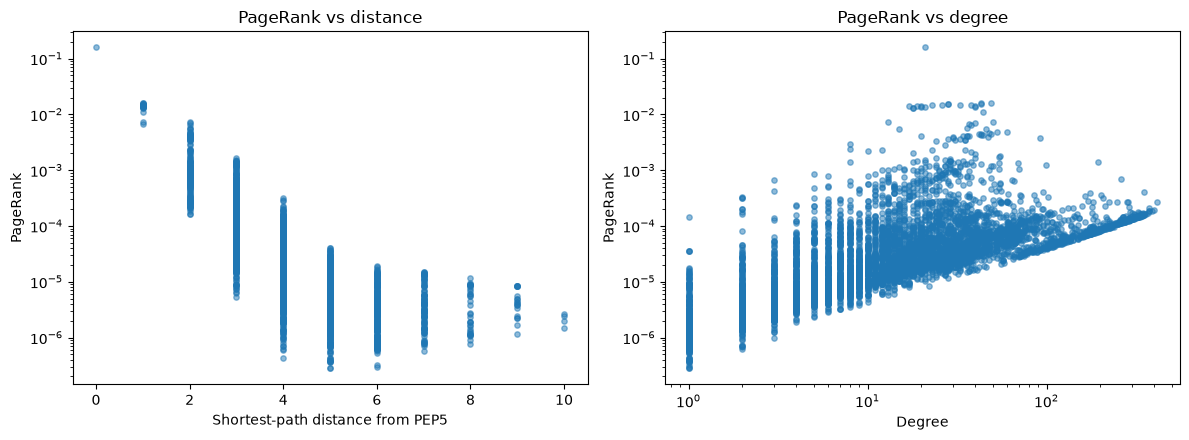

In [136]:
nodes = [n for n in G if n in distances if n not in essential_proteins]

pr   = [pagerank[n]  for n in nodes]
dist = [distances[n] for n in nodes]
deg  = [degrees[n]   for n in nodes]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(dist, pr, alpha=0.5, s=15)
axes[0].set_xlabel("Shortest-path distance from PEP5")
axes[0].set_ylabel("PageRank")
axes[0].set_yscale("log")
axes[0].set_title("PageRank vs distance")

axes[1].scatter(deg, pr, alpha=0.5, s=15)
axes[1].set_xlabel("Degree")
axes[1].set_ylabel("PageRank")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("PageRank vs degree")

plt.tight_layout()
plt.show()

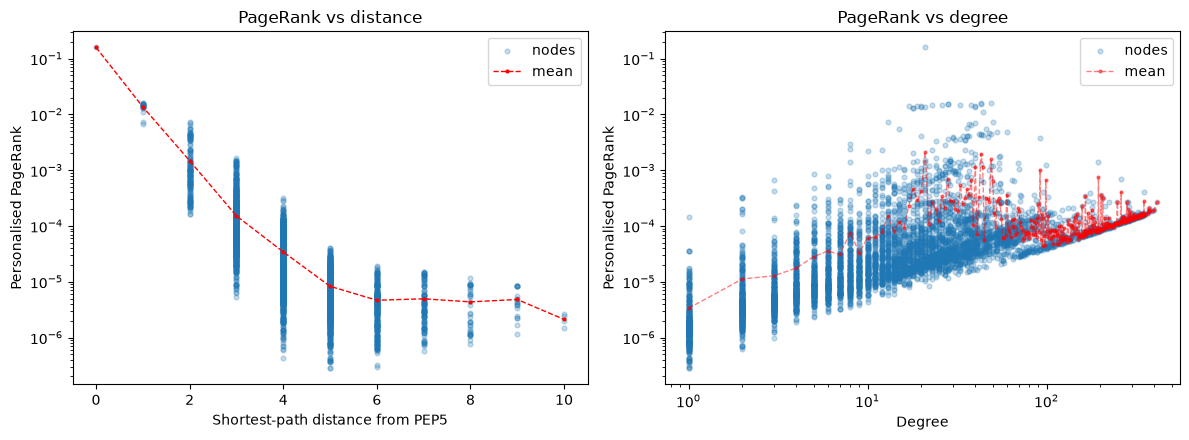

In [137]:
df = pd.DataFrame({
    "pagerank": [pagerank[n] for n in nodes],
    "distance": [distances[n] for n in nodes],
    "degree":   [degrees[n] for n in nodes],
})

mean_by_dist = df.groupby("distance")["pagerank"].mean()
mean_by_deg  = df.groupby("degree")["pagerank"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# PageRank vs distance
axes[0].scatter(df["distance"], df["pagerank"], alpha=0.25, s=12, label="nodes")
axes[0].plot(mean_by_dist.index, mean_by_dist.values,
             "o--", color="red", lw=1, ms=2, label="mean")
axes[0].set_xlabel("Shortest-path distance from PEP5")
axes[0].set_ylabel("Personalised PageRank")
axes[0].set_yscale("log")
axes[0].set_title("PageRank vs distance")
axes[0].legend()

# PageRank vs degree
axes[1].scatter(df["degree"], df["pagerank"], alpha=0.25, s=12, label="nodes")
axes[1].plot(mean_by_deg.index, mean_by_deg.values,
             "o--", color="red", lw=1, ms=2, label="mean", alpha=0.5)
axes[1].set_xlabel("Degree")
axes[1].set_ylabel("Personalised PageRank")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("PageRank vs degree")
axes[1].legend()

plt.tight_layout()
plt.savefig("wk10/pagerank_stats.png")
plt.show()

I suppose we are interested in those nodes that have uncharacteristically high page rank given their degree and distance.

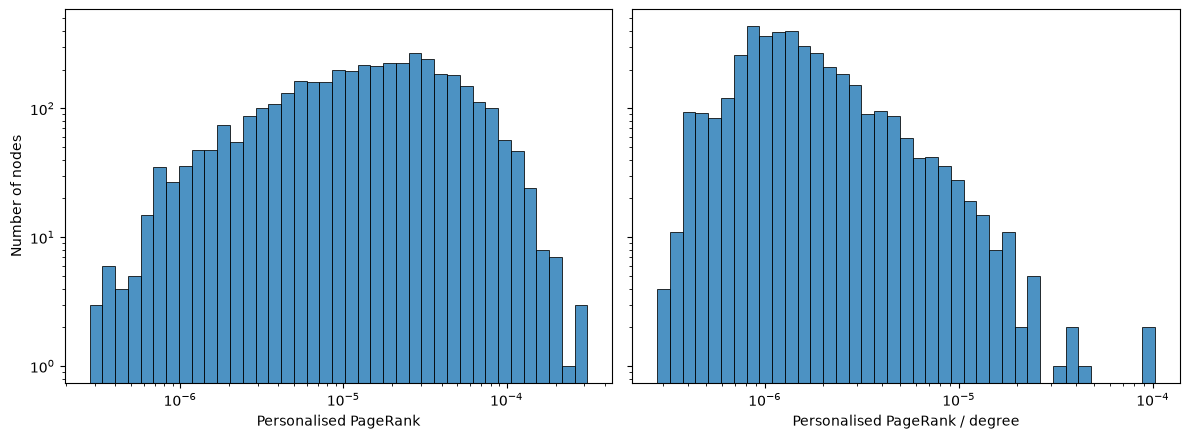

In [138]:
import numpy as np
import matplotlib.pyplot as plt

# Keep nodes with positive PageRank and nonzero degree so both arrays line up
nodes = [n for n in candidate_nodes if pagerank[n] > 0 and G.degree(n) > 0]

pr   = np.array([pagerank[n] for n in nodes])
pr_w = np.array([pagerank[n] / G.degree(n) for n in nodes])

def log_hist(ax, x, xlabel, color):
    bins = np.logspace(np.log10(x.min()), np.log10(x.max()), 40)
    ax.hist(x, bins=bins, edgecolor="black", linewidth=0.7, alpha=0.8, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(xlabel)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
log_hist(axes[0], pr,   "Personalised PageRank",           "tab:blue")
log_hist(axes[1], pr_w, "Personalised PageRank / degree",  "tab:blue")
axes[0].set_ylabel("Number of nodes")
plt.tight_layout()
plt.savefig("wk10/pagerank_histogram.png")
plt.show()

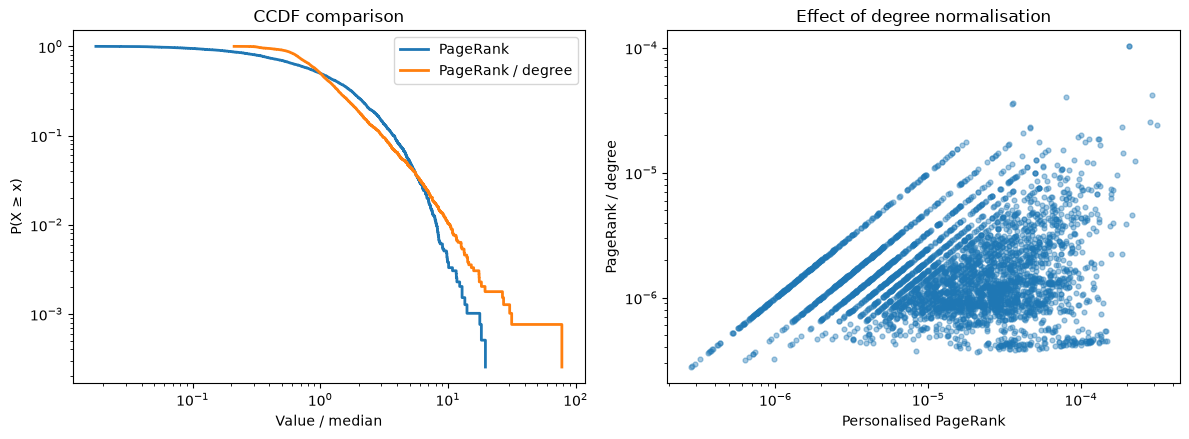

In [139]:
def ccdf(x):
    x = np.sort(x)
    return x, 1 - np.arange(len(x)) / len(x)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# CCDF overlay, rescaled by the median
for x, label in [(pr, "PageRank"), (pr_w, "PageRank / degree")]:
    xs, ys = ccdf(x / np.median(x))
    axes[0].step(xs, ys, where="post", label=label, lw=2)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("Value / median")
axes[0].set_ylabel("P(X ≥ x)")
axes[0].set_title("CCDF comparison")
axes[0].legend()

# Scatter: how each node moves
axes[1].scatter(pr, pr_w, s=12, alpha=0.4)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("Personalised PageRank")
axes[1].set_ylabel("PageRank / degree")
axes[1].set_title("Effect of degree normalisation")

plt.tight_layout()
plt.savefig("wk10/degree_normalisation.png")
plt.show()

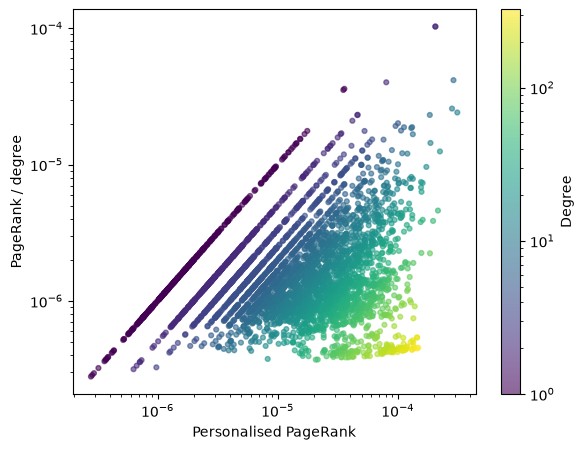

In [140]:
deg = np.array([G.degree(n) for n in nodes])

M = G.number_of_edges()
baseline = 1 / (2 * M)

fig, ax = plt.subplots(figsize=(6.5, 5))
sc = ax.scatter(
    pr, pr_w,
    c=deg,                                   # raw degree, not log10
    cmap="viridis",
    norm=LogNorm(vmin=deg.min(), vmax=deg.max()),
    s=12, alpha=0.6,
)
  
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Personalised PageRank")
ax.set_ylabel("PageRank / degree")
plt.colorbar(sc, label="Degree")
plt.savefig("wk10/pagerank_degree_cmap.png")
plt.show()

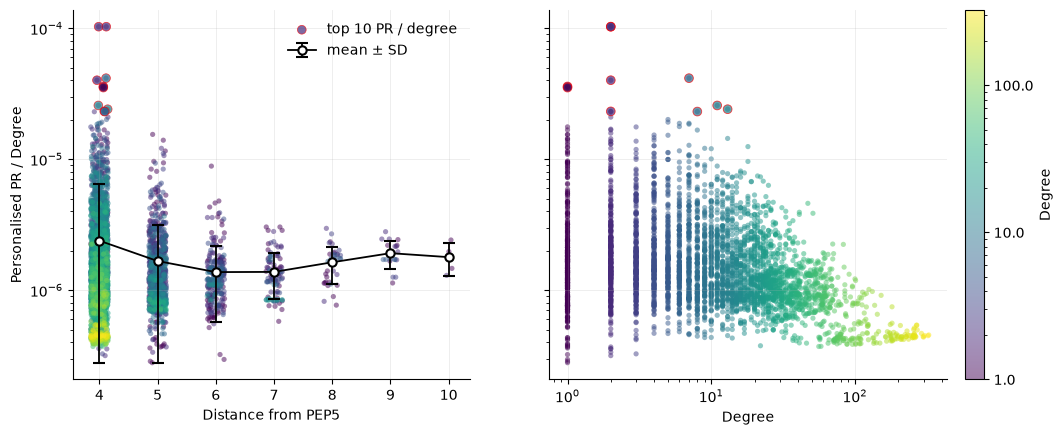

In [141]:
from matplotlib.colors import LogNorm
from matplotlib.ticker import ScalarFormatter

# ---------- Data ----------
nodes = [n for n in candidate_nodes
         if n in distances and pagerank[n] > 0]

df = pd.DataFrame({
    "node":        nodes,
    "distance":    [distances[n] for n in nodes],
    "degree":      [G.degree(n) for n in nodes],
    "weighted_PR": [pagerank[n] / G.degree(n) for n in nodes],
})

# Sort so hubs are drawn last; reset so the index is the row position
df = df.sort_values("degree").reset_index(drop=True)

top10 = df.nlargest(10, "weighted_PR")
top_idx = top10.index.to_numpy()

# Mean ± SD by distance, lower bar clipped for the log axis
floor = df["weighted_PR"].min()
grp = df.groupby("distance")["weighted_PR"]
stats_d = pd.DataFrame({"mean": grp.mean(), "sd": grp.std()}).dropna()
stats_d["lo"] = stats_d["mean"] - np.maximum(stats_d["mean"] - stats_d["sd"], floor)
stats_d["hi"] = stats_d["sd"]

# ---------- Plot setup ----------
cmap = "viridis"
norm = LogNorm(vmin=max(1, df["degree"].min()), vmax=df["degree"].max())
rng = np.random.default_rng(1)
jitter = rng.uniform(-0.15, 0.15, size=len(df))

scatter_kw = dict(c=df["degree"], cmap=cmap, norm=norm, s=14, alpha=0.5, linewidths=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)

# ---------- Left: by distance ----------
sc = axes[0].scatter(df["distance"] + jitter, df["weighted_PR"], zorder=1, **scatter_kw)
axes[0].scatter(top10["distance"] + jitter[top_idx], top10["weighted_PR"],
                c=top10["degree"], cmap=cmap, norm=norm,
                s=40, alpha=0.7, edgecolors="red", linewidths=0.5, zorder=4,
                label="top 10 PR / degree")
axes[0].errorbar(stats_d.index, stats_d["mean"],
                 yerr=[stats_d["lo"], stats_d["hi"]],
                 fmt="o-", color="black", lw=1.3, ms=6, mfc="white", mew=1.5,
                 capsize=4, capthick=1.5, label="mean ± SD", zorder=3)

axes[0].set_yscale("log")
axes[0].set_xticks(sorted(df["distance"].unique()))
axes[0].set_xlabel("Distance from PEP5")
axes[0].set_ylabel("Personalised PR / Degree")
axes[0].legend(frameon=False)

# ---------- Right: by degree ----------
axes[1].scatter(df["degree"], df["weighted_PR"], **scatter_kw)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("Degree")
axes[1].scatter(top10["degree"], top10["weighted_PR"], c=top10["degree"],
                cmap=cmap, norm=norm, s=40, alpha=0.7,
                edgecolors="red", linewidths=0.6, zorder=4)

# ---------- Shared styling ----------
for ax in axes:
    ax.grid(True, which="major", alpha=0.25, lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)

cb = fig.colorbar(sc, ax=axes, pad=0.02, fraction=0.04, label="Degree")
cb.ax.yaxis.set_major_formatter(ScalarFormatter())

plt.savefig("wk10/pr_by_distance_and_degree_top10.png", dpi=200, bbox_inches="tight")
plt.show()

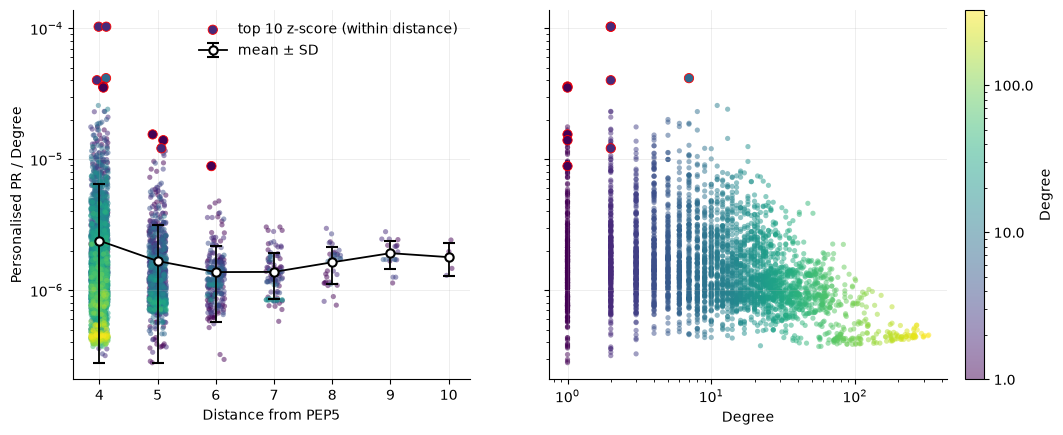

In [142]:
from matplotlib.colors import LogNorm
from matplotlib.ticker import ScalarFormatter

# ---------- Data ----------
alpha = 0.85
pr_global = nx.pagerank(G, alpha=alpha)

nodes = [n for n in candidate_nodes
         if n in distances and pagerank[n] > 0 and pr_global[n] > 0]

df = pd.DataFrame({
    "node":        nodes,
    "distance":    [distances[n] for n in nodes],
    "degree":      [G.degree(n) for n in nodes],
    "weighted_PR": [pagerank[n] / G.degree(n) for n in nodes],
})

# Sort so hubs are drawn last; reset so the index is the row position
df = df.sort_values("degree").reset_index(drop=True)

# Z-score within each distance group (log scale; use "weighted_PR" for raw)
df["logPR"] = np.log10(df["weighted_PR"])
g = df.groupby("distance")["logPR"]
df["z"] = (df["logPR"] - g.transform("mean")) / g.transform("std")

top10 = df.nlargest(10, "z")          # NaN z-scores are ignored
top_idx = top10.index.to_numpy()

# Mean ± SD by distance, lower bar clipped for the log axis
floor = df["weighted_PR"].min()
grp = df.groupby("distance")["weighted_PR"]
stats_d = pd.DataFrame({"mean": grp.mean(), "sd": grp.std()}).dropna()
stats_d["lo"] = stats_d["mean"] - np.maximum(stats_d["mean"] - stats_d["sd"], floor)
stats_d["hi"] = stats_d["sd"]

# ---------- Plot setup ----------
cmap = "viridis"
norm = LogNorm(vmin=max(1, df["degree"].min()), vmax=df["degree"].max())
rng = np.random.default_rng(1)
jitter = rng.uniform(-0.15, 0.15, size=len(df))

scatter_kw = dict(c=df["degree"], cmap=cmap, norm=norm, s=14, alpha=0.5, linewidths=0)
top_kw = dict(cmap=cmap, norm=norm, s=45, alpha=1,
              edgecolors="red", linewidths=0.6, zorder=4)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)

# ---------- Left: by distance ----------
sc = axes[0].scatter(df["distance"] + jitter, df["weighted_PR"], zorder=1, **scatter_kw)
axes[0].scatter(top10["distance"] + jitter[top_idx], top10["weighted_PR"],
                c=top10["degree"], label="top 10 z-score (within distance)", **top_kw)
axes[0].errorbar(stats_d.index, stats_d["mean"],
                 yerr=[stats_d["lo"], stats_d["hi"]],
                 fmt="o-", color="black", lw=1.3, ms=6, mfc="white", mew=1.5,
                 capsize=4, capthick=1.5, label="mean ± SD", zorder=3)

axes[0].set_yscale("log")
axes[0].set_xticks(sorted(df["distance"].unique()))
axes[0].set_xlabel("Distance from PEP5")
axes[0].set_ylabel("Personalised PR / Degree")
axes[0].legend(frameon=False)

# ---------- Right: by degree ----------
axes[1].scatter(df["degree"], df["weighted_PR"], zorder=1, **scatter_kw)
axes[1].scatter(top10["degree"], top10["weighted_PR"], c=top10["degree"], **top_kw)

axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("Degree")

# ---------- Shared styling ----------
for ax in axes:
    ax.grid(True, which="major", alpha=0.25, lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)

cb = fig.colorbar(sc, ax=axes, pad=0.02, fraction=0.04, label="Degree")
cb.ax.yaxis.set_major_formatter(ScalarFormatter())

plt.savefig("wk10/pr_by_distance_and_degree_zscore.png", dpi=200, bbox_inches="tight")
plt.show()

This looks really promising, we are killing off any nodes with really high degree, but still seeing nodes of larger degree in our top selection.

Another approach might be just to compare to global page-rank.

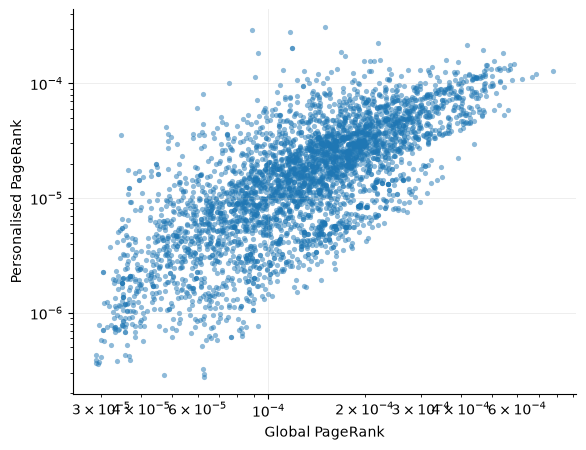

In [143]:
pr_global = nx.pagerank(G, alpha=0.85)  # same alpha as personalised run
nodes = [n for n in candidate_nodes
         if n in distances and pagerank[n] > 0 and pr_global[n] > 0]

df = pd.DataFrame({
    "node":            nodes,
    "personalised_PR": [pagerank[n] for n in nodes],
    "distance":        [distances[n] for n in nodes],
    "degree":          [G.degree(n) for n in nodes],
    "global":          [pr_global[n] for n in nodes],
    "enrichment":      [pagerank[n] / pr_global[n] for n in nodes],
})

fig, ax = plt.subplots(figsize=(6.5, 5))

ax.scatter(df["global"], df["personalised_PR"],
           color="tab:blue", s=14, alpha=0.5, linewidths=0)

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Global PageRank")
ax.set_ylabel("Personalised PageRank")
# ax.legend(frameon=False)

ax.grid(True, which="major", alpha=0.25, lw=0.6)
ax.spines[["top", "right"]].set_visible(False)

plt.savefig("wk10/global_vs_personalised_pr.png", dpi=200, bbox_inches="tight")
plt.show()

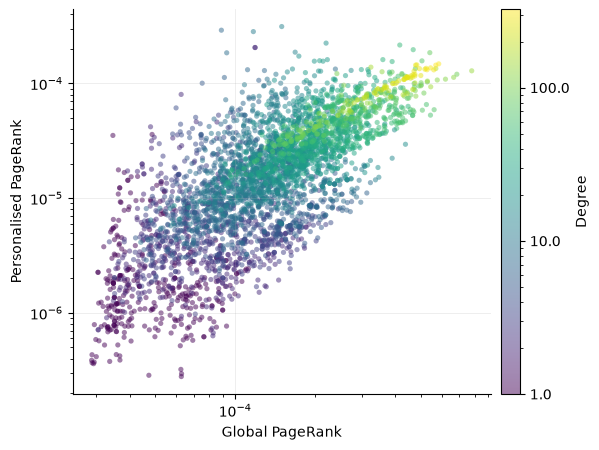

In [144]:
from matplotlib.colors import LogNorm
from matplotlib.ticker import ScalarFormatter
from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullFormatter

pr_global = nx.pagerank(G, alpha=0.85)  # same alpha as personalised run
nodes = [n for n in candidate_nodes
         if n in distances and pagerank[n] > 0 and pr_global[n] > 0]

df = pd.DataFrame({
    "node":            nodes,
    "personalised_PR": [pagerank[n] for n in nodes],
    "distance":        [distances[n] for n in nodes],
    "degree":          [G.degree(n) for n in nodes],
    "global":          [pr_global[n] for n in nodes],
    "enrichment":      [pagerank[n] / pr_global[n] for n in nodes],
})

# Sort so hubs are drawn last
df = df.sort_values("degree").reset_index(drop=True)

norm = LogNorm(vmin=max(1, df["degree"].min()), vmax=df["degree"].max())

fig, ax = plt.subplots(figsize=(6.5, 5))

sc = ax.scatter(df["global"], df["personalised_PR"],
                c=df["degree"], cmap="viridis", norm=norm,
                s=14, alpha=0.5, linewidths=0)

ax.set_xscale("log")
ax.set_yscale("log")

for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_locator(LogLocator(base=10, numticks=6))
    axis.set_major_formatter(LogFormatterMathtext())
    axis.set_minor_formatter(NullFormatter())
    

ax.set_xlabel("Global PageRank")
ax.set_ylabel("Personalised PageRank")

ax.grid(True, which="major", alpha=0.25, lw=0.6)
ax.spines[["top", "right"]].set_visible(False)

cb = fig.colorbar(sc, ax=ax, pad=0.02, label="Degree")
cb.ax.yaxis.set_major_formatter(ScalarFormatter())

plt.savefig("wk10/global_vs_personalised_pr_degree.png", dpi=200, bbox_inches="tight")
plt.show()

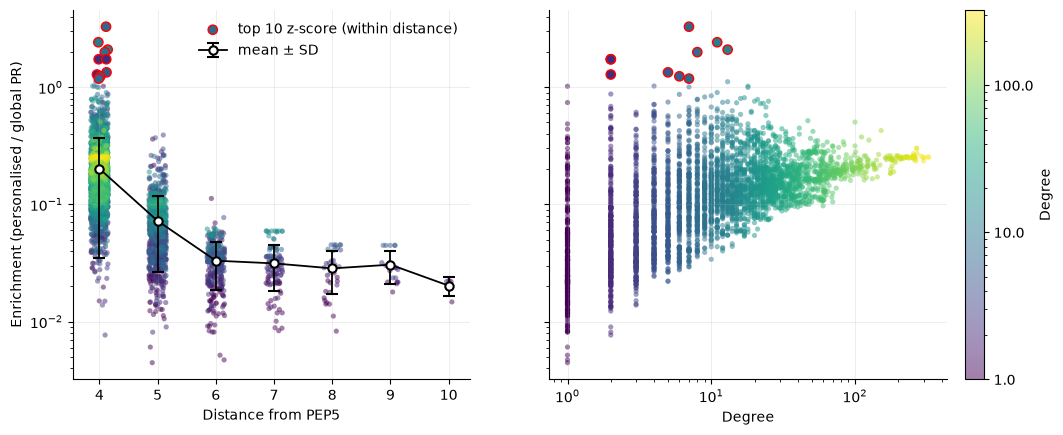

In [149]:
from matplotlib.colors import LogNorm
from matplotlib.ticker import ScalarFormatter, LogLocator, LogFormatterMathtext, NullFormatter

# ---------- Data ----------
alpha = 0.85
pr_global = nx.pagerank(G, alpha=alpha)

nodes = [n for n in candidate_nodes
         if n in distances and pagerank[n] > 0 and pr_global[n] > 0]

df = pd.DataFrame({
    "node":            nodes,
    "personalised_PR": [pagerank[n] for n in nodes],
    "distance":        [distances[n] for n in nodes],
    "degree":          [G.degree(n) for n in nodes],
    "global":          [pr_global[n] for n in nodes],
    "enrichment":      [pagerank[n] / pr_global[n] for n in nodes],
})

# Sort so hubs are drawn last; reset so the index is the row position
df = df.sort_values("degree").reset_index(drop=True)

# ---------- Log-space statistics ----------
df["log_enrich"] = np.log10(df["enrichment"])
g = df.groupby("distance")["log_enrich"]

# Z-score of each node relative to others at the same distance
df["z"] = (df["log_enrich"] - g.transform("mean")) / g.transform("std")

top10 = df.nlargest(10, "z")          # NaN z-scores are ignored
top_idx = top10.index.to_numpy()

# Raw mean ± SD per distance; lower bar clipped at the data minimum for the log axis
floor = df["enrichment"].min()
grp = df.groupby("distance")["enrichment"]
stats_d = pd.DataFrame({"mean": grp.mean(), "sd": grp.std(), "n": grp.size()}).dropna()
stats_d["lo"] = stats_d["mean"] - np.maximum(stats_d["mean"] - stats_d["sd"], floor)
stats_d["hi"] = stats_d["sd"]

# ---------- Plot setup ----------
cmap = "viridis"
norm = LogNorm(vmin=max(1, df["degree"].min()), vmax=df["degree"].max())
rng = np.random.default_rng(1)
jitter = rng.uniform(-0.15, 0.15, size=len(df))

scatter_kw = dict(c=df["degree"], cmap=cmap, norm=norm, s=14, alpha=0.5, linewidths=0)
top_kw = dict(cmap=cmap, norm=norm, s=45, alpha=1,
              edgecolors="red", linewidths=1.0, zorder=4)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)

# ---------- Left: by distance ----------
sc = axes[0].scatter(df["distance"] + jitter, df["enrichment"], zorder=1, **scatter_kw)
axes[0].scatter(top10["distance"] + jitter[top_idx], top10["enrichment"],
                c=top10["degree"], label="top 10 z-score (within distance)", **top_kw)
axes[0].errorbar(stats_d.index, stats_d["mean"],
                 yerr=[stats_d["lo"], stats_d["hi"]],
                 fmt="o-", color="black", lw=1.3, ms=6, mfc="white", mew=1.5,
                 capsize=4, capthick=1.5, label="mean ± SD", zorder=3)

axes[0].set_yscale("log")
axes[0].set_xticks(sorted(df["distance"].unique()))
axes[0].set_xlabel("Distance from PEP5")
axes[0].set_ylabel("Enrichment (personalised / global PR)")
axes[0].legend(frameon=False)

# ---------- Right: by degree ----------
axes[1].scatter(df["degree"], df["enrichment"], zorder=1, **scatter_kw)
axes[1].scatter(top10["degree"], top10["enrichment"], c=top10["degree"], **top_kw)

axes[1].set_xscale("log")
axes[1].set_xlabel("Degree")
axes[1].xaxis.set_major_locator(LogLocator(base=10, numticks=6))
axes[1].xaxis.set_major_formatter(LogFormatterMathtext())
axes[1].xaxis.set_minor_formatter(NullFormatter())

# ---------- Shared styling ----------
for ax in axes:
    ax.grid(True, which="major", alpha=0.25, lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)

cb = fig.colorbar(sc, ax=axes, pad=0.02, fraction=0.04, label="Degree")
cb.ax.yaxis.set_major_formatter(ScalarFormatter())

plt.savefig("wk10/global_normalisation_zscore.png", dpi=200, bbox_inches="tight")
plt.show()

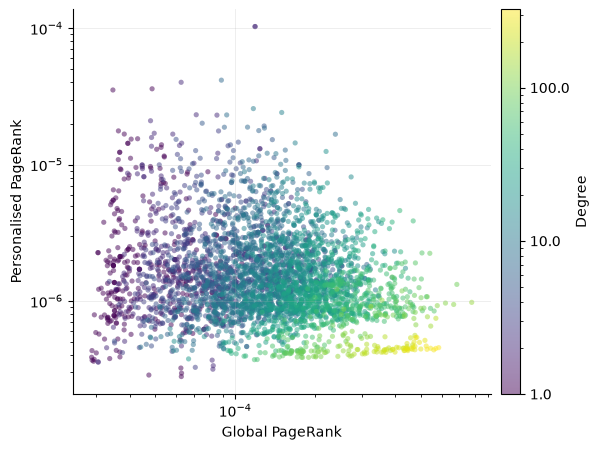

In [ ]:
from matplotlib.colors import LogNorm
from matplotlib.ticker import ScalarFormatter
from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullFormatter

pr_global = nx.pagerank(G, alpha=0.85)  # same alpha as personalised run
nodes = [n for n in candidate_nodes
         if n in distances and pagerank[n] > 0 and pr_global[n] > 0]

df = pd.DataFrame({
    "node":            nodes,
    "personalised_PR": [pagerank[n] for n in nodes],
    "distance":        [distances[n] for n in nodes],
    "degree":          [G.degree(n) for n in nodes],
    "global":          [pr_global[n] for n in nodes],
    "enrichment":      [pagerank[n] / pr_global[n] for n in nodes],
})

# Sort so hubs are drawn last
df = df.sort_values("degree").reset_index(drop=True)

norm = LogNorm(vmin=max(1, df["degree"].min()), vmax=df["degree"].max())

fig, ax = plt.subplots(figsize=(6.5, 5))

sc = ax.scatter(df["global"], df["personalised_PR"]/df['degree'],
                c=df["degree"], cmap="viridis", norm=norm,
                s=14, alpha=0.5, linewidths=0)

ax.set_xscale("log")
ax.set_yscale("log")

for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_locator(LogLocator(base=10, numticks=6))
    axis.set_major_formatter(LogFormatterMathtext())
    axis.set_minor_formatter(NullFormatter())
    

ax.set_xlabel("Global PageRank")
ax.set_ylabel("Personalised PageRank")

ax.grid(True, which="major", alpha=0.25, lw=0.6)
ax.spines[["top", "right"]].set_visible(False)

cb = fig.colorbar(sc, ax=ax, pad=0.02, label="Degree")
cb.ax.yaxis.set_major_formatter(ScalarFormatter())

plt.savefig("wk10/global_vs_personalised_pr_degree.png", dpi=200, bbox_inches="tight")
plt.show()